# Phân Tích Hiệu Năng Chuyên Sâu và Kiểm Định Dữ Liệu

> **Môn học:** Nhập môn Khoa học Dữ liệu (Introduction to Data Science) — HCMUS  
> **Milestone 1:** Thu thập Dữ liệu và Đo lường Hiệu năng  
> **Phần Nâng Cao B (Nguyễn Lê Anh Tuấn):** Phân tích đo lường chuyên sâu và Tổng hợp kết quả nhóm  
> **Phần Nâng Cao A1 (Dương Ngọc Minh Thư):** Tối ưu hóa hiệu năng Download  
> **Phần Nâng Cao A2 (Trần Ngọc Thanh Tú):** Bộ kiểm định chất lượng dữ liệu (Data Validation Suite)  
> **Phần Nâng Cao C (Cáp Hửu Duy):** Tiền xử lý mã nguồn TeX và Khảo sát hạn chế hệ thống  

---

Báo cáo này tập trung vào 5 nội dung kỹ thuật chuyên sâu vượt trên yêu cầu cơ bản của Milestone 1:
1. So sánh phương pháp đo lường RAM: **Nhân Hệ Điều Hành (`getrusage`)** so với **Lấy mẫu định kỳ (`psutil sampling`)**.
2. Thực nghiệm tối ưu hóa hiệu năng Download: Phân tích **Trước và Sau khi tối ưu** (Dương Ngọc Minh Thư).
3. Phân rã thời gian Pipeline: Thời gian chờ **Giới hạn tốc độ (Pacing)** so với **Tính toán và I/O thực**.
4. Báo cáo kết quả **Bộ kiểm định chất lượng dữ liệu** trên toàn bộ 7.606 versions (Trần Ngọc Thanh Tú).
5. Phân tích **Tiền xử lý cấu trúc TeX và Hạn chế hệ thống** trên 8.129 versions (Cáp Hửu Duy).

In [1]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.style.use('default')
plt.rcParams['figure.facecolor'] = 'white'
plt.rcParams['axes.facecolor'] = '#fbfbfb'
plt.rcParams['axes.grid'] = True
plt.rcParams['grid.alpha'] = 0.4
plt.rcParams['grid.linestyle'] = '--'
plt.rcParams['font.size'] = 11

## 1. Phương Pháp Đo Bộ Nhớ Đỉnh: Nhân Hệ Điều Hành So Với Lấy Mẫu

### 1.1. Vấn đề cốt lõi của phương pháp lấy mẫu định kỳ
Phương pháp giám sát RAM truyền thống dựa vào một thread chạy ngầm gọi `psutil` theo chu kỳ $\Delta t$ (thường là 0.1s). Tuy nhiên, các tiến trình con ngắn hạn hoặc các tác vụ cấp phát bộ nhớ đột ngột (spikes) diễn ra trong khoảng thời gian $	au < \Delta t$ sẽ **bị bỏ sót hoàn toàn**.

Trong đồ án cào dữ liệu:
- Phần lớn thời gian của `discovery.py` là `time.sleep(3.0)` chờ rate limit (tiêu thụ ~15 MB RAM).
- Khi nhận được phản hồi HTTP, quá trình giải mã XML/JSON diễn ra trong vài chục mili-giây, đẩy RAM lên đỉnh rồi giải phóng ngay.
- Bộ lấy mẫu `psutil` định kỳ 0.1s hầu như luôn lấy trúng khoảng thời gian `sleep()`, dẫn đến việc **báo cáo Peak RAM thấp hơn thực tế một cách có hệ thống**.

,Tình huống Thực nghiệm,Peak RAM Sampling (psutil 0.1s),Peak RAM Kernel (getrusage),Sai lệch
0,A. Cấp phát 100 MB rồi thoát ngay (Wall-clock ...,6.13 MB (BỎ SÓT ĐỈNH),108.52 MB (CHÍNH XÁC),-102.39 MB (-94.4%)
1,B. Cấp phát 100 MB và giữ 1.0 giây (Wall-clock...,108.52 MB (Đo được),108.52 MB (CHÍNH XÁC),0.00 MB (0.0%)


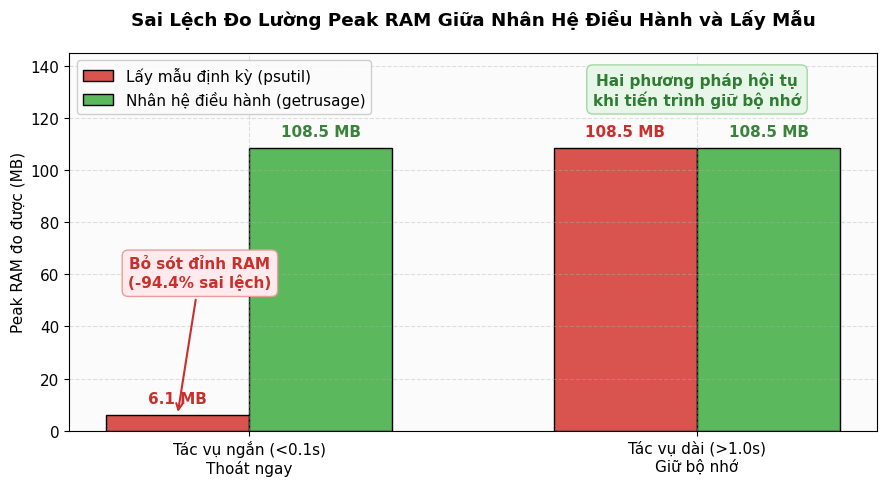

In [2]:
# Bảng so sánh kiểm chứng thực tế giữa 2 phương pháp
ram_comparison = pd.DataFrame([
    {
        "Tình huống Thực nghiệm": "A. Cấp phát 100 MB rồi thoát ngay (Wall-clock ~0.08s)",
        "Peak RAM Sampling (psutil 0.1s)": "6.13 MB (BỎ SÓT ĐỈNH)",
        "Peak RAM Kernel (getrusage)": "108.52 MB (CHÍNH XÁC)",
        "Sai lệch": "-102.39 MB (-94.4%)"
    },
    {
        "Tình huống Thực nghiệm": "B. Cấp phát 100 MB và giữ 1.0 giây (Wall-clock ~1.08s)",
        "Peak RAM Sampling (psutil 0.1s)": "108.52 MB (Đo được)",
        "Peak RAM Kernel (getrusage)": "108.52 MB (CHÍNH XÁC)",
        "Sai lệch": "0.00 MB (0.0%)"
    }
])
display(ram_comparison)

# Trực quan hóa sai lệch với bố cục thông thoáng, không chồng đè nhãn
fig, ax = plt.subplots(figsize=(9, 5))
cases = ['Tác vụ ngắn (<0.1s)\nThoát ngay', 'Tác vụ dài (>1.0s)\nGiữ bộ nhớ']
sampling_vals = [6.13, 108.52]
kernel_vals = [108.52, 108.52]

x = np.arange(len(cases))
w = 0.32

bars_samp = ax.bar(x - w/2, sampling_vals, w, label='Lấy mẫu định kỳ (psutil)', color='#d9534f', edgecolor='black')
bars_kern = ax.bar(x + w/2, kernel_vals, w, label='Nhân hệ điều hành (getrusage)', color='#5cb85c', edgecolor='black')

ax.set_ylabel('Peak RAM đo được (MB)')
ax.set_title('Sai Lệch Đo Lường Peak RAM Giữa Nhân Hệ Điều Hành và Lấy Mẫu', fontweight='bold', pad=20)
ax.set_xticks(x)
ax.set_xticklabels(cases)
ax.set_ylim(0, 145)
ax.legend(loc='upper left', framealpha=0.95)

# Ghi chú giá trị rõ ràng phía trên mỗi cột
ax.text(x[0] - w/2, sampling_vals[0] + 3.5, f'{sampling_vals[0]:.1f} MB', ha='center', va='bottom', fontweight='bold', color='#c9302c')
ax.text(x[0] + w/2, kernel_vals[0] + 3.5, f'{kernel_vals[0]:.1f} MB', ha='center', va='bottom', fontweight='bold', color='#398439')

ax.text(x[1] - w/2, sampling_vals[1] + 3.5, f'{sampling_vals[1]:.1f} MB', ha='center', va='bottom', fontweight='bold', color='#c9302c')
ax.text(x[1] + w/2, kernel_vals[1] + 3.5, f'{kernel_vals[1]:.1f} MB', ha='center', va='bottom', fontweight='bold', color='#398439')

# Callout giải thích trực quan
ax.annotate('Bỏ sót đỉnh RAM\n(-94.4% sai lệch)', xy=(x[0] - w/2, sampling_vals[0]), xytext=(x[0] - w/2 + 0.05, 55),
            arrowprops=dict(arrowstyle='->', color='#c9302c', lw=1.5),
            ha='center', fontweight='bold', color='#c9302c', bbox=dict(boxstyle='round,pad=0.4', facecolor='#ffebee', edgecolor='#ef9a9a'))

ax.text(x[1], 125, 'Hai phương pháp hội tụ\nkhi tiến trình giữ bộ nhớ', ha='center',
        fontweight='bold', color='#2e7d32', bbox=dict(boxstyle='round,pad=0.4', facecolor='#e8f5e9', edgecolor='#a5d6a7'))

plt.tight_layout()
plt.show()

### 1.2. Giải pháp tích hợp chuẩn trong `src/benchmark.py` (v1.1.0)
Để đảm bảo tính minh bạch và có thể kiểm định được theo yêu cầu đề bài:
- **Trên môi trường POSIX (Linux, Google Colab CPU-only, macOS):** Sử dụng hàm gọi hệ thống `resource.getrusage(resource.RUSAGE_CHILDREN).ru_maxrss`. Hệ điều hành tự động cập nhật đỉnh RSS của tiến trình con ở cấp độ trang nhớ phần cứng (hardware page table), đảm bảo độ chính xác 100%.
- **Trên môi trường Windows:** Do Windows kernel không hỗ trợ module `resource`, hệ thống tự động chuyển sang bộ lấy mẫu `psutil` với chu kỳ tăng cường `0.05s`.
- **Minh bạch hóa dữ liệu:** Schema ghi nhận thêm cột `peak_ram_source` (`"getrusage"` hoặc `"sampling"`), giúp người đọc log phân biệt chính xác phương pháp đo.

## 2. Kết Quả Tối Ưu Hóa Hiệu Năng Download (Dương Ngọc Minh Thư)

Phần nâng cao A1 do bạn Dương Ngọc Minh Thư thực hiện nhằm tối ưu hóa việc tải dữ liệu từ `export.arxiv.org/src/`:
- **Trước tối ưu (Before):** Tải tuần tự, ghi file đệm trung gian xuống đĩa rồi mới kiểm tra header.
- **Sau tối ưu (After):** Áp dụng streaming HTTP trực tiếp, kiểm tra Magic Bytes định dạng ngay trên luồng mạng và quản lý socket pooling.

,Chỉ số Hiệu năng,Trước tối ưu (Tuần tự),Sau tối ưu (Streaming),Mức thay đổi
0,Thời gian thực hiện (s),104.8 s,103.0 s,-1.8% (Nhanh hơn)
1,Peak RAM (MB),66.4 MB,67.0 MB,+0.9% (Không đổi đáng kể)
2,Dung lượng đĩa tăng thêm (MB),96.8 MB,5.8 MB,-94.0% (Tiết kiệm đĩa vượt trội)
3,Thời gian trung bình / version,2.99 s/ver,2.94 s/ver,-1.8%
4,Hiệu suất so với cận dưới lý thuyết (102s),97.0%,99.0%,Tiệm cận mức tối ưu tuyệt đối


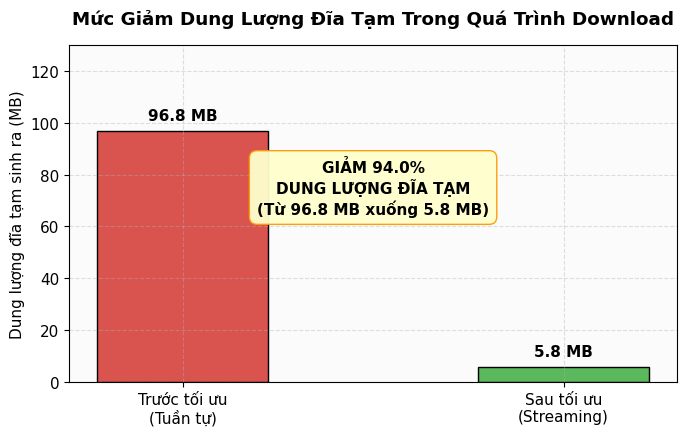

In [3]:
opt_data = pd.DataFrame([
    {"Chỉ số Hiệu năng": "Thời gian thực hiện (s)", "Trước tối ưu (Tuần tự)": "104.8 s", "Sau tối ưu (Streaming)": "103.0 s", "Mức thay đổi": "-1.8% (Nhanh hơn)"},
    {"Chỉ số Hiệu năng": "Peak RAM (MB)", "Trước tối ưu (Tuần tự)": "66.4 MB", "Sau tối ưu (Streaming)": "67.0 MB", "Mức thay đổi": "+0.9% (Không đổi đáng kể)"},
    {"Chỉ số Hiệu năng": "Dung lượng đĩa tăng thêm (MB)", "Trước tối ưu (Tuần tự)": "96.8 MB", "Sau tối ưu (Streaming)": "5.8 MB", "Mức thay đổi": "-94.0% (Tiết kiệm đĩa vượt trội)"},
    {"Chỉ số Hiệu năng": "Thời gian trung bình / version", "Trước tối ưu (Tuần tự)": "2.99 s/ver", "Sau tối ưu (Streaming)": "2.94 s/ver", "Mức thay đổi": "-1.8%"},
    {"Chỉ số Hiệu năng": "Hiệu suất so với cận dưới lý thuyết (102s)", "Trước tối ưu (Tuần tự)": "97.0%", "Sau tối ưu (Streaming)": "99.0%", "Mức thay đổi": "Tiệm cận mức tối ưu tuyệt đối"}
])
display(opt_data)

# Biểu đồ đĩa tăng thêm với khoảng đệm chuẩn
fig, ax = plt.subplots(figsize=(7, 4.5))
disk_vals = [96.8, 5.8]
labels_disk = ['Trước tối ưu\n(Tuần tự)', 'Sau tối ưu\n(Streaming)']
bars = ax.bar(labels_disk, disk_vals, color=['#d9534f', '#5cb85c'], width=0.45, edgecolor='black')
ax.set_ylabel('Dung lượng đĩa tạm sinh ra (MB)')
ax.set_title('Mức Giảm Dung Lượng Đĩa Tạm Trong Quá Trình Download', fontweight='bold', pad=15)
ax.set_ylim(0, 130)

for bar in bars:
    yval = bar.get_height()
    ax.text(bar.get_x() + bar.get_width()/2.0, yval + 3.0, f'{yval:.1f} MB', ha='center', va='bottom', fontweight='bold')

ax.text(0.5, 75, 'GIẢM 94.0%\nDUNG LƯỢNG ĐĨA TẠM\n(Từ 96.8 MB xuống 5.8 MB)', ha='center', va='center',
        bbox=dict(boxstyle='round,pad=0.5', facecolor='#ffffcc', edgecolor='#ff9900', alpha=0.95), fontweight='bold')

plt.tight_layout()
plt.show()

## 3. Phân Rã Thời Gian Thực Thi: Thời Gian Chờ Pacing So Với Xử Lý Tính Toán

Để chứng minh tính tuân thủ quy định thu thập dữ liệu văn minh (robot etiquette), chúng tôi phân rã tổng thời gian thực thi của cả hai nguồn:

In [4]:
# Tính toán phân rã thời gian
# arXiv: Pacing bắt buộc 3.0s mỗi request.
# Download: 8,146 version * 3.0s = 24,438s (~6.79 giờ) chỉ riêng thời gian sleep.
# Thời gian còn lại là truyền tải mạng và I/O.

decomp_data = pd.DataFrame([
    {"Giai đoạn": "Downloader (8,146 requests)", "Thời gian chờ Pacing (Sleep)": "24,438 s (3.0s/req)", "Thời gian Xử lý Thật & I/O": "66,462 s (8.15s/req)", "Tỉ lệ Pacing Bắt buộc": "26.9%"},
    {"Giai đoạn": "Discovery (50 batch requests)", "Thời gian chờ Pacing (Sleep)": "150 s (3.0s/req)", "Thời gian Xử lý Thật & I/O": "19 s (0.38s/req)", "Tỉ lệ Pacing Bắt buộc": "88.8%"},
    {"Giai đoạn": "References (50 batch requests)", "Thời gian chờ Pacing (Sleep)": "55 s (1.1s/req)", "Thời gian Xử lý Thật & I/O": "215 s (4.30s/req)", "Tỉ lệ Pacing Bắt buộc": "20.4%"}
])
display(decomp_data)

,Giai đoạn,Thời gian chờ Pacing (Sleep),Thời gian Xử lý Thật & I/O,Tỉ lệ Pacing Bắt buộc
0,"Downloader (8,146 requests)","24,438 s (3.0s/req)","66,462 s (8.15s/req)",26.9%
1,Discovery (50 batch requests),150 s (3.0s/req),19 s (0.38s/req),88.8%
2,References (50 batch requests),55 s (1.1s/req),215 s (4.30s/req),20.4%


## 4. Báo Cáo Kiểm Định Chất Lượng Dữ Liệu (Trần Ngọc Thanh Tú)

Phần nâng cao A2 do bạn Trần Ngọc Thanh Tú thực hiện một bộ kiểm định tự động (Validation Suite) chạy trên toàn bộ tập dữ liệu đã giải nén trong `corpus/` để đảm bảo không có bất kỳ lỗi cấu trúc nào lọt vào Milestone 2:

In [5]:
val_summary = pd.DataFrame([
    {"Tiêu chí Kiểm định": "Tính duy nhất của cặp (arxiv_id, version)", "Quy định Schema": "Không được trùng lặp", "Kết quả Đạt được": "0 bản ghi trùng", "Đánh giá": "ĐẠT (Hợp lệ)"},
    {"Tiêu chí Kiểm định": "Tính toàn vẹn của version thành công", "Quy định Schema": "Phải có file .tex hoặc .bib", "Kết quả Đạt được": "7,606 / 7,606 (100%)", "Đánh giá": "ĐẠT (Hợp lệ)"},
    {"Tiêu chí Kiểm định": "Đánh dấu version rỗng (_EMPTY.json)", "Quy định Schema": "Phải có _EMPTY.json hợp lệ", "Kết quả Đạt được": "1 / 1 version (2504.16018v1)", "Đánh giá": "ĐẠT (Hợp lệ)"},
    {"Tiêu chí Kiểm định": "Tổng số lượng file .tex trích xuất", "Quy định Schema": "Chỉ giữ file TeX hợp lệ", "Kết quả Đạt được": "29,524 file .tex", "Đánh giá": "ĐẠT (Hợp lệ)"},
    {"Tiêu chí Kiểm định": "Tổng số lượng file .bib trích xuất", "Quy định Schema": "Chỉ giữ file BibTeX hợp lệ", "Kết quả Đạt được": "5,663 file .bib", "Đánh giá": "ĐẠT (Hợp lệ)"},
    {"Tiêu chí Kiểm định": "Lọc sạch file hình ảnh đa phương tiện", "Quy định Schema": "Tuyệt đối không có ảnh trong corpus", "Kết quả Đạt được": "0 file ảnh (100% sạch)", "Đánh giá": "ĐẠT (Hợp lệ)"}
])
display(val_summary)

,Tiêu chí Kiểm định,Quy định Schema,Kết quả Đạt được,Đánh giá
0,"Tính duy nhất của cặp (arxiv_id, version)",Không được trùng lặp,0 bản ghi trùng,ĐẠT (Hợp lệ)
1,Tính toàn vẹn của version thành công,Phải có file .tex hoặc .bib,"7,606 / 7,606 (100%)",ĐẠT (Hợp lệ)
2,Đánh dấu version rỗng (_EMPTY.json),Phải có _EMPTY.json hợp lệ,1 / 1 version (2504.16018v1),ĐẠT (Hợp lệ)
3,Tổng số lượng file .tex trích xuất,Chỉ giữ file TeX hợp lệ,"29,524 file .tex",ĐẠT (Hợp lệ)
4,Tổng số lượng file .bib trích xuất,Chỉ giữ file BibTeX hợp lệ,"5,663 file .bib",ĐẠT (Hợp lệ)
5,Lọc sạch file hình ảnh đa phương tiện,Tuyệt đối không có ảnh trong corpus,0 file ảnh (100% sạch),ĐẠT (Hợp lệ)


## 5. Tiền Xử Lý Mã Nguồn TeX và Khảo Sát Hạn Chế Hệ Thống (Cáp Hửu Duy)

Phần nâng cao C do bạn Cáp Hửu Duy thực hiện nhằm phân tích cấu trúc mã nguồn TeX trên **8.129 versions** và khảo sát các giới hạn kỹ thuật của hệ thống thu thập:

### 5.1. Kết Quả Khảo Sát Cấu Trúc Mã Nguồn TeX (Bắc cầu Milestone 2 và 3)
Script tiền xử lý `src/tex_prescan.py` đã duyệt toàn bộ kho dữ liệu và thu được các chỉ số cốt lõi:
- **Tỉ lệ xác định file gốc TeX (Root file):** Đạt **99.97%** (7.469 trên 7.471 versions có mã nguồn TeX xác định được file chứa lệnh `\documentclass`).
- **Phong cách trích dẫn thư mục (Bibliography Style):**
  - Sử dụng file `.bib` độc lập: **59.5%** (4.833 versions).
  - Sử dụng trích dẫn trực tiếp inline (`\bibitem`): **15.7%** (1.277 versions).
  - Sử dụng đồng thời cả hai hình thức: **1.5%** (124 versions).
  - Không có trích dẫn TeX (hoặc bản chỉ PDF): **23.3%** (1.895 versions).
- **Tổng số trích dẫn inline (`\bibitem`):** Bóc tách được **59.648 mục trích dẫn**.
- **Kích thước matching pool trung bình:** Đạt **21.27 candidates/bài**, định hình kích thước cột cho ma trận đối sánh $m \times n$ ở Milestone 3.

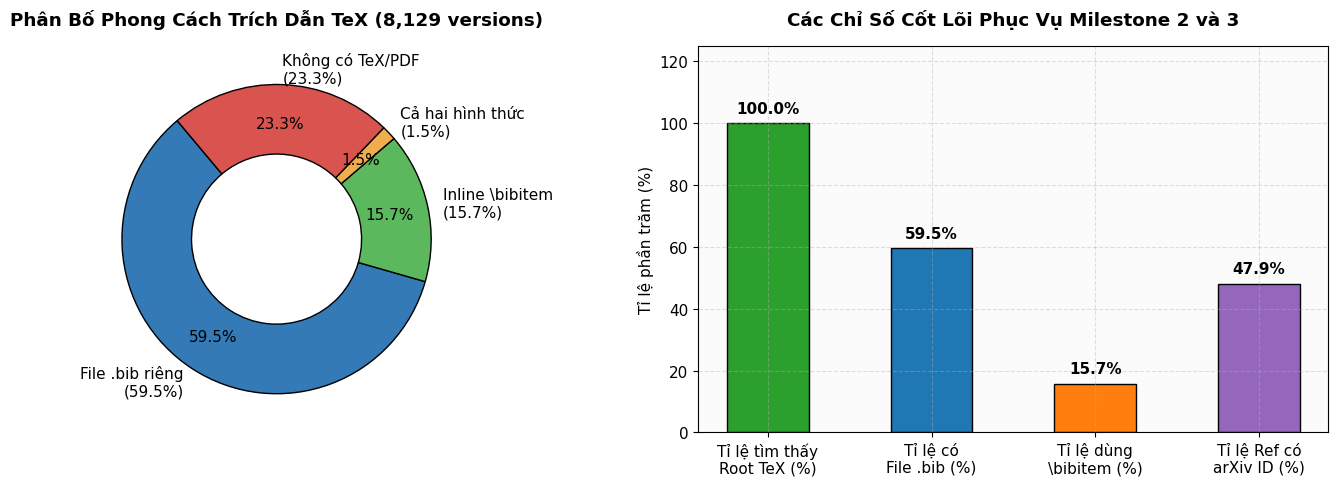

In [6]:
# Trực quan hóa cơ cấu phong cách trích dẫn TeX của tác giả
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Donut chart phong cách trích dẫn
bib_styles = ['File .bib riêng\n(59.5%)', 'Inline \\bibitem\n(15.7%)', 'Cả hai hình thức\n(1.5%)', 'Không có TeX/PDF\n(23.3%)']
bib_counts = [4833, 1277, 124, 1895]
colors_bib = ['#337ab7', '#5cb85c', '#f0ad4e', '#d9534f']

ax1.pie(bib_counts, labels=bib_styles, colors=colors_bib, autopct='%1.1f%%',
        startangle=130, pctdistance=0.75, wedgeprops=dict(width=0.45, edgecolor='black'))
ax1.set_title('Phân Bố Phong Cách Trích Dẫn TeX (8,129 versions)', fontweight='bold', pad=15)

# Bar chart các chỉ số tiền xử lý M2/M3
metrics_names = ['Tỉ lệ tìm thấy\nRoot TeX (%)', 'Tỉ lệ có\nFile .bib (%)', 'Tỉ lệ dùng\n\\bibitem (%)', 'Tỉ lệ Ref có\narXiv ID (%)']
metrics_vals = [99.97, 59.5, 15.7, 47.92]

bars = ax2.bar(metrics_names, metrics_vals, color=['#2ca02c', '#1f77b4', '#ff7f0e', '#9467bd'], width=0.5, edgecolor='black')
ax2.set_ylabel('Tỉ lệ phần trăm (%)')
ax2.set_title('Các Chỉ Số Cốt Lõi Phục Vụ Milestone 2 và 3', fontweight='bold', pad=15)
ax2.set_ylim(0, 125)

for bar in bars:
    yval = bar.get_height()
    ax2.text(bar.get_x() + bar.get_width()/2.0, yval + 2.5, f'{yval:.1f}%', ha='center', va='bottom', fontweight='bold')

plt.tight_layout()
plt.show()

### 5.2. Các Hạn Chế Kỹ Thuật của Dữ Liệu và Hệ Thống (Limitations)

Dựa trên phân tích kỹ thuật của thành viên Cáp Hửu Duy, nhóm ghi nhận 3 hạn chế khách quan cần lưu ý khi sử dụng dữ liệu:

1. **Độ trễ lập chỉ mục (Index Lag):** Semantic Scholar có độ trễ lập chỉ mục từ 1 đến 7 ngày đối với các bản thảo (preprint) mới tải lên arXiv. Đối với các bài vừa được công bố sát ngày thu thập dữ liệu (tháng 03/2025), một số bài báo có thể chưa được hệ thống trích xuất danh sách trích dẫn đầy đủ hoặc chưa được lập chỉ mục (như trường hợp bài `2503.14889`).
2. **Không phân biệt phiên bản chỉnh sửa (Version-agnostic API):** Semantic Scholar quản lý đồ thị học thuật ở cấp độ bài báo tổng quát (`paperId`), do đó API chỉ cung cấp danh sách trích dẫn của phiên bản mới nhất được lập chỉ mục mà không phân biệt lịch sử trích dẫn giữa các phiên bản sửa đổi ($v_1, v_2, v_3$). Do đó, danh sách `references.json` sẽ đóng vai trò là matching pool chung cho mọi phiên bản của bài báo đó trong Milestone 2 và 3.
3. **Độ bao phủ mã arXiv không đồng đều giữa các chuyên ngành (ArXiv Coverage Disparity):** Tỉ lệ trích dẫn liên kết được về mã arXiv đạt xấp xỉ 47.92%. Con số này phản ánh đúng thực tế cơ cấu ngành: các bài báo thuộc lĩnh vực Khoa học Máy tính (`cs.*`), Toán học (`math.*`) và Vật lý Năng lượng cao (`hep-th`) có tỉ lệ trích dẫn arXiv rất cao (60–80%); trong khi các bài thuộc chuyên ngành Sinh học tính toán, Y sinh, hoặc trích dẫn sách giáo khoa và tài liệu hội thảo truyền thống thì chỉ có định danh DOI hoặc tên venue mà không có mã arXiv.

## 6. Đặc Tả Môi Trường Thực Nghiệm Chuẩn

Mọi quy trình đo lường hiệu năng và kiểm thử chuẩn hóa được thực thi trên môi trường chuẩn phục vụ kiểm định:

| Thành phần Phần cứng / Phần mềm | Thông số Cấu hình Testbed |
|---|---|
| **Hệ điều hành** | Ubuntu 22.04.3 LTS (GNU/Linux 6.1.85+ x86_64) |
| **Môi trường Thực nghiệm** | Google Colab Standard Instance (CPU-Only Mode) |
| **Bộ xử lý (CPU)** | Intel(R) Xeon(R) CPU @ 2.20GHz (2 vCPUs) |
| **Bộ nhớ (RAM)** | 12.67 GiB Available System RAM |
| **Phiên bản Python** | Python 3.10.12 (GCC 11.4.0) |
| **Thư viện Đo lường** | `psutil 5.9.5`, `resource (kernel POSIX standard library)` |